# Settings

In [257]:
run_beamforming = True
beamform_interpolated = True

parameters_file_path = "./parameters/002_simulation.json"

#virtual space settings

blood_density = 1060
frames = 100

# Imports

In [258]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import json
from scipy import signal

# Import parameters

In [259]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [260]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"]

    return params

In [261]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = 1500 #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.010008000000000001 m


# Create virtual space

In [262]:
virtual_space = np.zeros((params["rf"]["samples"], params["array"]["length"]))
virtual_space.shape

(834, 128)

In [263]:
angle = 25
vein_length = 0.006
vein = np.random.rand(2000)
starting_x = 40 * params["array"]["pitch"] #mm
starting_y = 0.005 #mm

starting_x_idx = int(starting_x / params["array"]["pitch"])
starting_y_idx = int((starting_y / C) * params["rf"]["sampling_rate"])

print(f"Starting x : {starting_x} m / Starting x idx : {starting_x_idx}")
print(f"Starting y : {starting_y} s / Starting y idx : {starting_y_idx}")

Starting x : 0.0036000000000000003 m / Starting x idx : 40
Starting y : 0.005 s / Starting y idx : 208


In [264]:
for i in range(0, len(vein)):
    x_pos = (i * (vein_length / len(vein))) * np.sin(angle * np.pi / 180)
    y_pos = (i * (vein_length / len(vein))) * np.cos(angle * np.pi / 180)

    x_idx = int(x_pos / params["array"]["pitch"])
    y_idx = int((y_pos / C) * params["rf"]["sampling_rate"])

    virtual_space[starting_y_idx + y_idx, starting_x_idx + x_idx] = vein[i]

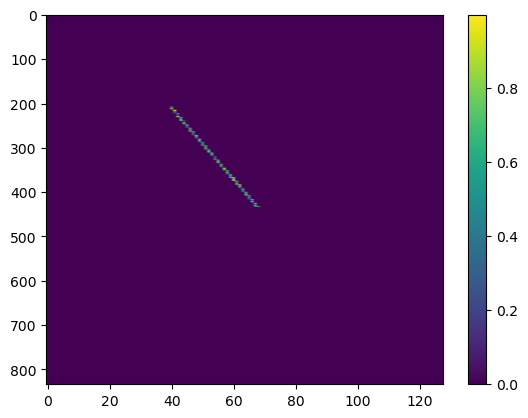

In [265]:
plt.imshow(virtual_space, aspect='auto')
plt.colorbar()